# LightShift-PatchCore — 03 · B2 (alignement) + B3 (seuil conforme)

**CPU · ResNet-18 gelé · MVTec AD · bottle / carpet / metal_nut · MLflow**

Ce notebook reprend **strictement les banques PatchCore, les splits et la fonction de perturbation du notebook 02**. Il compare sur les mêmes images : **Vanilla, B2, B3 et B2+B3**.

**Protocole sans fuite :** `source_train` pour les statistiques source ; `target_calibration` est partitionné en un sous-ensemble d'alignement **B2** et un sous-ensemble de calibration **B3**, disjoints ; `target_test` est réservé aux métriques finales. Les seuils sont fixés *avant* d'évaluer les images test. Les perturbations photométriques sont déterministes et les fichiers originaux ne sont jamais modifiés.

**B4 est prévu dans le projet** : adaptateur résiduel 1×1 appris sur CPU, à implémenter dans un notebook dédié après B1 et les ablations initiales. Il n'est **pas** entraîné dans ce notebook 03.

## Étape 1 — Imports, chemins, configuration et reproductibilité

Détecte les mêmes chemins Docker que les notebooks 01/02. Aucun recalcul de la banque.

In [1]:
from pathlib import Path
import os, json, random, time, hashlib, platform, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
from scipy.ndimage import gaussian_filter
from skimage.measure import label, regionprops
from tqdm import tqdm
import yaml

WORKSPACE = Path('/workspace') if Path('/workspace/notebooks').is_dir() else Path.cwd().resolve().parent
NOTEBOOKS_DIR = WORKSPACE/'notebooks' if (WORKSPACE/'notebooks').is_dir() else Path.cwd()
BASELINE_DIR = NOTEBOOKS_DIR/'artifacts_baseline'
LIGHTING_DIR = NOTEBOOKS_DIR/'artifacts_lighting'
MODELS_DIR = WORKSPACE/'models' if (WORKSPACE/'models').is_dir() else NOTEBOOKS_DIR/'models'
OUTPUT_DIR = NOTEBOOKS_DIR/'artifacts_b2_b3'
for part in ['config', 'metrics', 'figures', 'stats']:
    (OUTPUT_DIR/part).mkdir(parents=True, exist_ok=True)
BASELINE_CONFIG = NOTEBOOKS_DIR/'configs'/'baseline_cpu.yaml'
assert BASELINE_CONFIG.exists(), f'Configuration 01 introuvable : {BASELINE_CONFIG}'
CFG = yaml.safe_load(BASELINE_CONFIG.read_text(encoding='utf-8'))
CATEGORIES = list(CFG['categories'])
IMAGE_SIZE = int(CFG['image_size'])
SEED = int(CFG['seed'])
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
DEVICE = torch.device('cpu')
assert CFG['backbone']=='resnet18' and CFG['layers']==['layer2','layer3']
print('CPU :',DEVICE,'| Python :',platform.python_version(),'| Torch :',torch.__version__)
print('Catégories :',CATEGORIES,'| Taille :',IMAGE_SIZE)

CPU : cpu | Python : 3.11.18 | Torch : 2.15.0+cu132
Catégories : ['bottle', 'carpet', 'metal_nut'] | Taille : 224


## Étape 2 — Charger splits/banques et vérifier les fichiers de sortie du notebook 02

Le fichier `lighting_results.csv` n'est utilisé que comme **référence d'audit**, jamais pour ajuster les paramètres sur le test.

In [2]:
def locate_mvtec_root(base, categories):
    base = Path(base)
    candidates = [base, base.parent, WORKSPACE/'data']
    for root in list(candidates):
        if root.is_dir():
            candidates += [p for p in root.glob('*') if p.is_dir()]
            candidates += [p for p in root.glob('*/*') if p.is_dir()]
    for path in dict.fromkeys(candidates):
        if all((path/cat/'train'/'good').is_dir() for cat in categories):
            return path
    return None

MVTEC_ROOT = locate_mvtec_root(CFG['data_root'], CATEGORIES)
assert MVTEC_ROOT is not None, 'Dataset MVTec AD introuvable'
SPLITS, BANKS, KNN = {}, {}, {}
for cat in CATEGORIES:
    split_file = BASELINE_DIR/'splits'/f'{cat}_splits.json'
    bank_file = MODELS_DIR/f'{cat}_resnet18_cpu_bank.npy'
    assert split_file.exists() and bank_file.exists(), f'Splits ou banque manquants : {cat}'
    payload = json.loads(split_file.read_text(encoding='utf-8'))
    SPLITS[cat] = {part: [MVTEC_ROOT/relative for relative in paths] for part,paths in payload.items()}
    assert set(SPLITS[cat])=={'source_train','source_val','target_calibration','target_test'}
    all_paths=[str(p.resolve()) for paths in SPLITS[cat].values() for p in paths]
    assert len(all_paths)==len(set(all_paths)), f'Fuite de données : {cat}'
    assert all(p.is_file() for paths in SPLITS[cat].values() for p in paths), f'Images manquantes : {cat}'
    BANKS[cat] = np.load(bank_file,allow_pickle=False).astype(np.float32)
    KNN[cat] = NearestNeighbors(n_neighbors=1,algorithm='brute',metric='euclidean',n_jobs=1).fit(BANKS[cat])

LIGHTING_RESULTS = LIGHTING_DIR/'metrics'/'lighting_results.csv'
if LIGHTING_RESULTS.exists():
    lighting_summary=pd.read_csv(LIGHTING_RESULTS)
    print('Notebook 02 :',len(lighting_summary),'lignes de diagnostic disponibles')
else:
    warnings.warn('Résultats notebook 02 absents : on peut continuer avec les banques/splits du notebook 01')
display(pd.DataFrame([{'category':cat,**{k:len(v) for k,v in SPLITS[cat].items()},'bank_patches':len(BANKS[cat])} for cat in CATEGORIES]))

Notebook 02 : 48 lignes de diagnostic disponibles


,category,source_train,source_val,target_calibration,target_test,bank_patches
0,bottle,146,31,32,83,256
1,carpet,196,42,42,117,256
2,metal_nut,154,33,33,115,256


## Étape 3 — Recharger EXACTEMENT le backbone et les prétraitements

Pas d'entraînement ni de modification des poids ; `layer2/layer3` et la concaténation restent identiques à la baseline.

In [3]:
weights = ResNet18_Weights.DEFAULT
mean,std = weights.transforms().mean,weights.transforms().std
image_transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE),interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),transforms.Normalize(mean=mean,std=std)])
mask_transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE),interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor()])

class FeatureExtractor(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone=resnet18(weights=weights).to(DEVICE).eval()
        self.features={}
        self.hooks=[]
        for name in CFG['layers']:
            self.hooks.append(getattr(self.backbone,name).register_forward_hook(
                lambda module, inputs, output, key=name: self.features.__setitem__(key,output)))
        for p in self.backbone.parameters(): p.requires_grad_(False)

    @torch.inference_mode()
    def forward(self, x):
        self.features.clear()
        self.backbone(x.to(DEVICE))
        ref=self.features['layer2']
        items=[ref]
        for name in CFG['layers']:
            if name!='layer2':
                items.append(F.interpolate(self.features[name],size=ref.shape[-2:],mode='bilinear',align_corners=False))
        return torch.cat(items,dim=1)

extractor=FeatureExtractor()

def feature_to_patches(x):
    return x.squeeze(0).permute(1,2,0).reshape(-1,x.shape[1]).cpu().numpy().astype(np.float32)

def load_mask(path,category):
    if path.parent.name=='good': return np.zeros((IMAGE_SIZE,IMAGE_SIZE),dtype=np.uint8)
    mask_path=MVTEC_ROOT/category/'ground_truth'/path.parent.name/(path.stem+'_mask.png')
    if not mask_path.exists(): raise FileNotFoundError(mask_path)
    with Image.open(mask_path) as im: arr=mask_transform(im.convert('L')).squeeze(0).numpy()
    return (arr>0).astype(np.uint8)

for cat in CATEGORIES:
    with Image.open(SPLITS[cat]['source_val'][0]) as im:
        fm=extractor(image_transform(im.convert('RGB')).unsqueeze(0))
    assert int(fm.shape[1])==int(BANKS[cat].shape[1]),f'Incompatibilité des features pour {cat}'
print('Backbone et banques compatibles.')

Backbone et banques compatibles.


## Étape 4 — Reproduire les 5 perturbations du notebook 02

Mêmes formules et même graine, y compris le choix d'angle pour l'ombrage. **Ne pas altérer les masques**.

In [4]:
def apply_lighting_shift(rgb_image, kind='clean', severity=0, image_key=''):
    x=np.asarray(rgb_image.convert('RGB'),dtype=np.float32)/255.0
    if kind=='clean' or severity==0: return rgb_image.convert('RGB').copy()
    assert severity in (1,3,5)
    t=severity/5.0
    if kind=='brightness': x=x*(1.0-0.65*t)
    elif kind=='contrast': x=(x-0.5)*(1.0-0.80*t)+0.5
    elif kind=='gamma': x=np.power(x,1.0+1.8*t)
    elif kind=='color_temperature':
        gains=np.array([1+0.38*t,1+0.04*t,1-0.38*t],dtype=np.float32)
        x=x*gains[None,None,:]
    elif kind=='directional_shading':
        key=hashlib.sha256(f'{SEED}|{image_key}'.encode()).digest()
        angle=int.from_bytes(key[:4],'big')/2**32*2*np.pi
        h,w=x.shape[:2]
        xx=np.linspace(-1,1,w,dtype=np.float32)[None,:]
        yy=np.linspace(-1,1,h,dtype=np.float32)[:,None]
        gradient=(xx*np.cos(angle)+yy*np.sin(angle))/np.sqrt(2)
        factor=np.clip(1.0-0.65*t+0.60*t*gradient,0.20,1.15)
        x=x*factor[...,None]
    else: raise ValueError(kind)
    return Image.fromarray(np.uint8(np.round(np.clip(x,0,1)*255)),mode='RGB')

@torch.inference_mode()
def extract_fmap(path,kind='clean',severity=0):
    with Image.open(path) as im:
        rgb=apply_lighting_shift(im,kind,severity,str(path.relative_to(MVTEC_ROOT)))
    return extractor(image_transform(rgb).unsqueeze(0))

SHIFTS=['brightness','contrast','gamma','color_temperature','directional_shading']
ALL_CONDITIONS=[('clean',0)]+[(kind,sev) for kind in SHIFTS for sev in (1,3,5)]
print('Conditions :',len(ALL_CONDITIONS))

Conditions : 16


## Étape 5 — Configuration CPU et séparation stricte B2/B3

Par défaut, pour chaque catégorie : **8 images normales cibles pour estimer B2**, puis **20 autres images normales cibles pour calibrer B3**. Ces images viennent uniquement de `target_calibration`, et leur identité est figée **avant toute évaluation**.

⚠️ Pour `alpha = 0.05`, B3 exige **au moins 19 scores de calibration** pour un seuil conforme fini. Avec moins d'images, la règle conforme renvoie un seuil infini (aucune alerte), et cela doit être rapporté — jamais masqué.

`FAST_MODE=True` limite les conditions pour un premier test CPU ; remettre `False` pour l'étude complète.

In [5]:
ALPHA=0.05
N_SOURCE_STATS=12
N_B2_ALIGN=8
N_B3_CALIB=20
FAST_MODE=True
FAST_CONDITIONS=[('clean',0),('brightness',5),('contrast',5),('directional_shading',5)]
CONDITIONS=FAST_CONDITIONS if FAST_MODE else ALL_CONDITIONS
PIXEL_METRICS=False  # True : pixel AUROC + heatmaps (coût RAM/CPU important)
B2_EPS=1e-6
LOG_TO_MLFLOW=True

PROTOCOL=dict(seed=SEED,alpha=ALPHA,n_source_stats=N_SOURCE_STATS,n_b2_align=N_B2_ALIGN,
              n_b3_calib=N_B3_CALIB,fast_mode=FAST_MODE,conditions=CONDITIONS,
              pixel_metrics=PIXEL_METRICS,b2_epsilon=B2_EPS,
              backbone=CFG['backbone'],layers=CFG['layers'],image_size=IMAGE_SIZE,
              source_config=str(BASELINE_CONFIG))
(OUTPUT_DIR/'config'/'b2_b3_cpu.yaml').write_text(yaml.safe_dump(PROTOCOL,sort_keys=False,allow_unicode=True),encoding='utf-8')

SOURCE_STATS_PATHS={}; B2_PATHS={}; B3_PATHS={}
for cat in CATEGORIES:
    source_paths=list(SPLITS[cat]['source_train'])
    calib_paths=list(SPLITS[cat]['target_calibration'])
    assert len(source_paths)>=N_SOURCE_STATS,f'Pas assez de source_train : {cat}'
    assert len(calib_paths)>=N_B2_ALIGN+N_B3_CALIB, f'Calibration insuffisante {cat} : {len(calib_paths)}'
    rng=np.random.default_rng(SEED)
    SOURCE_STATS_PATHS[cat]=[source_paths[i] for i in sorted(rng.choice(len(source_paths),N_SOURCE_STATS,replace=False))]
    order=np.random.default_rng(SEED).permutation(len(calib_paths))
    B2_PATHS[cat]=[calib_paths[i] for i in order[:N_B2_ALIGN]]
    B3_PATHS[cat]=[calib_paths[i] for i in order[N_B2_ALIGN:N_B2_ALIGN+N_B3_CALIB]]
    s2={str(p.resolve()) for p in B2_PATHS[cat]}
    s3={str(p.resolve()) for p in B3_PATHS[cat]}
    st={str(p.resolve()) for p in SPLITS[cat]['target_test']}
    assert not (s2&s3 or s2&st or s3&st),f'Fuite B2/B3 : {cat}'
    payload={'source_stats':[str(p.relative_to(MVTEC_ROOT)) for p in SOURCE_STATS_PATHS[cat]],
             'b2_alignment':[str(p.relative_to(MVTEC_ROOT)) for p in B2_PATHS[cat]],
             'b3_calibration':[str(p.relative_to(MVTEC_ROOT)) for p in B3_PATHS[cat]]}
    (OUTPUT_DIR/'config'/f'{cat}_adaptation_split.json').write_text(json.dumps(payload,indent=2),encoding='utf-8')
display(pd.DataFrame([{'category':c,'source_stats':len(SOURCE_STATS_PATHS[c]),
                       'b2_alignment':len(B2_PATHS[c]),'b3_calibration':len(B3_PATHS[c]),
                       'test':len(SPLITS[c]['target_test'])} for c in CATEGORIES]))

,category,source_stats,b2_alignment,b3_calibration,test
0,bottle,12,8,20,83
1,carpet,12,8,20,117
2,metal_nut,12,8,20,115


## Étape 6 — B2 : estimer moyennes et écarts-types source/cible

Pour les features concaténées `layer2/layer3` **avant** kNN, utiliser :

\[ z_{align}=(z_{cible}-\mu_{cible})\frac{\sigma_{source}}{\max(\sigma_{cible},\varepsilon)}+\mu_{source} \]

Les statistiques cibles sont calculées sur **8 images normales du nouvel éclairage**. Aucun paramètre n'est optimisé sur le test.

In [6]:
@torch.inference_mode()
def estimate_channel_stats(paths,kind='clean',severity=0):
    # Agrégation de moments par canal sur les patchs de chaque image.
    count=0; sum_x=None; sum_x2=None
    for path in paths:
        z=feature_to_patches(extract_fmap(path,kind,severity)).astype(np.float64)
        if sum_x is None:
            sum_x=np.zeros(z.shape[1],dtype=np.float64)
            sum_x2=np.zeros(z.shape[1],dtype=np.float64)
        sum_x+=z.sum(axis=0);sum_x2+=np.square(z).sum(axis=0);count+=len(z)
    assert count>0
    mu=sum_x/count
    sd=np.sqrt(np.maximum(sum_x2/count-np.square(mu),0.0))
    return mu.astype(np.float32),sd.astype(np.float32)

def align_features(fmap,src_stats,tgt_stats):
    src_mu,src_sd=src_stats;tgt_mu,tgt_sd=tgt_stats
    x=feature_to_patches(fmap)
    corrected=(x-tgt_mu[None,:])*(src_sd[None,:]/np.maximum(tgt_sd[None,:],B2_EPS))+src_mu[None,:]
    return corrected.astype(np.float32)

SOURCE_STATS={}
for cat in CATEGORIES:
    SOURCE_STATS[cat]=estimate_channel_stats(SOURCE_STATS_PATHS[cat])
    np.savez_compressed(OUTPUT_DIR/'stats'/f'{cat}_source_stats.npz',mu=SOURCE_STATS[cat][0],sd=SOURCE_STATS[cat][1])
    print(cat,'source channels:',len(SOURCE_STATS[cat][0]))

# Validation de l'alignement : si les stats source et cible sont identiques, B2 est l'identité.
test_arr=np.random.default_rng(SEED).normal(size=(30,len(SOURCE_STATS[CATEGORIES[0]][0]))).astype(np.float32)
mu,sd=SOURCE_STATS[CATEGORIES[0]]
ident=(test_arr-mu)*(sd/np.maximum(sd,B2_EPS))+mu
assert np.allclose(test_arr,ident,rtol=1e-4,atol=1e-4)
print('Test identité B2 : OK')

bottle source channels: 384
carpet source channels: 384
metal_nut source channels: 384
Test identité B2 : OK


## Étape 7 — Scores PatchCore : Vanilla et B2 sur les mêmes images

On extrait les features **une seule fois** par image ; deux recherches kNN produisent deux scores et deux heatmaps. Aucun changement de la banque mémoire.

In [7]:
def score_patches(patches,category,make_heatmap=False):
    d,_=KNN[category].kneighbors(patches,return_distance=True)
    side=int(round(np.sqrt(len(d))))
    assert side*side==len(d), 'La grille de patchs devrait être carrée'
    scores=d[:,0].reshape(side,side)
    image_score=float(scores.max())
    if not make_heatmap:return image_score,None
    up=F.interpolate(torch.from_numpy(scores.astype(np.float32))[None,None],size=(IMAGE_SIZE,IMAGE_SIZE),mode='bilinear',align_corners=False)[0,0].numpy()
    return image_score,gaussian_filter(up,float(CFG['pixel_smoothing_sigma'])).astype(np.float32)

@torch.inference_mode()
def predict_both(path,category,kind,severity,target_stats,make_heatmap=False):
    fmap=extract_fmap(path,kind,severity)
    vanilla=feature_to_patches(fmap)
    aligned=align_features(fmap,SOURCE_STATS[category],target_stats)
    return score_patches(vanilla,category,make_heatmap),score_patches(aligned,category,make_heatmap)

print('Scoring Vanilla + B2 prêt.')

def compute_aupro(gt_masks,pred_maps,fpr_limit=0.30,thresholds_count=80):
    gt=np.asarray(gt_masks,dtype=bool); scores=np.asarray(pred_maps,dtype=np.float32)
    neg=(~gt).sum()
    if neg==0:return float('nan')
    comps=[]
    for i in range(len(gt)):
        for reg in regionprops(label(gt[i],connectivity=2)):
            xy=reg.coords;comps.append((i,xy[:,0],xy[:,1]))
    if not comps:return float('nan')
    ths=np.linspace(float(scores.max())+1e-6,float(scores.min())-1e-6,thresholds_count)
    fprs=[0.0];pros=[0.0]
    for th in ths:
        pred=scores>=th
        fprs.append(float((pred & (~gt)).sum()/neg))
        pros.append(float(np.mean([pred[i,ys,xs].mean() for i,ys,xs in comps])))
        if fprs[-1]>=fpr_limit:break
    x=np.asarray(fprs);y=np.asarray(pros);order=np.argsort(x);x=x[order];y=y[order]
    uniq=np.unique(x); vals=np.array([y[x==u].max() for u in uniq])
    if uniq[-1]<fpr_limit:
        uniq=np.append(uniq,fpr_limit);vals=np.append(vals,vals[-1])
    grid=np.unique(np.r_[0.0,fpr_limit,uniq[(uniq>0)&(uniq<fpr_limit)]])
    return float(np.trapezoid(np.interp(grid,uniq,vals),grid)/fpr_limit)

Scoring Vanilla + B2 prêt.


## Étape 8 — B3 : quantile conforme, calcul exact et tests unitaires

Si l'on dispose de `n` scores **normaux cibles** échangeables avec une nouvelle image normale, le seuil (règle stricte `score > seuil`) est la **k-ième plus petite valeur**, avec \(k=\lceil(n+1)(1-\alpha)\rceil\). Si \(k>n\), aucun seuil fini ne garantit le niveau nominal avec cette règle : on retourne `+inf`.

Le FPR visé est **marginal**, pas une garantie conditionnelle sur une image ou une condition future différente. Aucun seuil oracle basé sur les étiquettes du test.

In [8]:
def conformal_normal_threshold(normal_scores,alpha=0.05):
    s=np.asarray(normal_scores,dtype=np.float64)
    assert s.ndim==1 and len(s)>0 and np.isfinite(s).all()
    assert 0<alpha<1
    n=len(s)
    k=int(np.ceil((n+1)*(1-alpha)-1e-12))
    if k>n:return float('inf')
    return float(np.sort(s)[k-1])

assert np.isinf(conformal_normal_threshold([1,2,3,4,5],0.05))
assert conformal_normal_threshold(np.arange(20),0.05)==19.0
assert conformal_normal_threshold([1,2,3,4,5],0.5)==3.0
print('Tests B3 : OK ; n=20, alpha=0.05 -> seuil maximal parmi les 20 scores.')

Tests B3 : OK ; n=20, alpha=0.05 -> seuil maximal parmi les 20 scores.


## Étape 9 — Estimation B2 et calibration B3 par condition

Pour chaque couple (catégorie, éclairage), on calcule les statistiques cibles avec `B2_PATHS`, puis **deux seuils conformes indépendants** (scores Vanilla et scores B2) avec `B3_PATHS`. Cette séparation évite que B2 apprenne des statistiques des mêmes images servant à sa calibration B3.

In [9]:
ADAPTATION={}
for cat in CATEGORIES:
    for kind,sev in CONDITIONS:
        key=(cat,kind,sev)
        tic=time.perf_counter()
        stats=estimate_channel_stats(B2_PATHS[cat],kind,sev)
        normal_v=[];normal_b2=[]
        for p in tqdm(B3_PATHS[cat],desc=f'Calib {cat} {kind} s{sev}',leave=False):
            (v,_),(b2,_)=predict_both(p,cat,kind,sev,stats,False)
            normal_v.append(v);normal_b2.append(b2)
        th_v=conformal_normal_threshold(normal_v,ALPHA)
        th_b2=conformal_normal_threshold(normal_b2,ALPHA)
        ADAPTATION[key]={'target_stats':stats,'threshold_vanilla':th_v,
                         'threshold_b2':th_b2,'cal_scores_v':normal_v,'cal_scores_b2':normal_b2,
                         'adapt_seconds':time.perf_counter()-tic}
        np.savez_compressed(OUTPUT_DIR/'stats'/f'{cat}_{kind}_s{sev}_target_stats.npz',mu=stats[0],sd=stats[1])
        print(cat,kind,sev,'B3 threshold:',round(th_v,4),'B2+B3 threshold:',round(th_b2,4))
print('Nombre de conditions calibrées :',len(ADAPTATION))

bottle clean 0 B3 threshold: 6.2121 B2+B3 threshold: 6.147


bottle brightness 5 B3 threshold: 4.7705 B2+B3 threshold: 5.3514


bottle contrast 5 B3 threshold: 4.1059 B2+B3 threshold: 4.961


bottle directional_shading 5 B3 threshold: 6.2544 B2+B3 threshold: 6.2088


carpet clean 0 B3 threshold: 3.5508 B2+B3 threshold: 3.6015


carpet brightness 5 B3 threshold: 4.2228 B2+B3 threshold: 6.8299


... (2 outputs left out)

metal_nut clean 0 B3 threshold: 5.9491 B2+B3 threshold: 5.9831


metal_nut brightness 5 B3 threshold: 5.6343 B2+B3 threshold: 5.971


metal_nut contrast 5 B3 threshold: 5.6696 B2+B3 threshold: 6.1764


metal_nut directional_shading 5 B3 threshold: 5.509 B2+B3 threshold: 6.1314
Nombre de conditions calibrées : 12


### Étape 10a — Seuils SOURCE enregistrés dans le notebook 02 (avant test)

On reprend ses trois seuils **tels quels** et on vérifie leur provenance. La baseline avait utilisé le quantile empirique source `np.quantile(..., 1-alpha)` ; ce seuil n'a pas de garantie conforme.

In [10]:
SOURCE_FILE=LIGHTING_DIR/'config'/'source_thresholds.json'
assert SOURCE_FILE.exists(),f'Seuils source notebook 02 manquants : {SOURCE_FILE}'
source_payload=json.loads(SOURCE_FILE.read_text(encoding='utf-8'))
assert abs(float(source_payload['alpha'])-ALPHA)<1e-10,'Alpha différent du notebook 02'
SOURCE_THRESHOLDS={cat:float(source_payload['thresholds'][cat]) for cat in CATEGORIES}
assert all(np.isfinite(v) for v in SOURCE_THRESHOLDS.values())
display(pd.DataFrame([{'category':c,'source_threshold':SOURCE_THRESHOLDS[c]} for c in CATEGORIES]))

,category,source_threshold
0,bottle,4.585290
1,carpet,3.590598
2,metal_nut,5.414710


## Étape 10 — Évaluation comparative sur `target_test`

Quatre méthodes sur les **mêmes images test** :

- **Vanilla** : features et seuil source inchangés ;
- **B2** : features alignées, seuil source inchangé (diagnostic, seuil pas nécessairement cohérent après B2) ;
- **B3** : features Vanilla, seuil conforme cible ;
- **B2+B3** : features alignées, seuil conforme recalibré sur les scores alignés.

**B3 seul ne modifie pas l'AUROC** ; B2 et B2+B3 ont le même AUROC. Nous évaluons tous les seuils sur test uniquement après calibration. Au départ `PIXEL_METRICS=False` pour limiter le coût CPU.

In [11]:
METRICS_PATH=OUTPUT_DIR/'metrics'/'b2_b3_results.csv'
RESULTS=[]
for cat in CATEGORIES:
    test_paths=SPLITS[cat]['target_test']
    labels=np.asarray([int(p.parent.name!='good') for p in test_paths],dtype=np.uint8)
    masks=np.stack([load_mask(p,cat) for p in test_paths]) if PIXEL_METRICS else None
    for kind,sev in CONDITIONS:
        key=(cat,kind,sev); item=ADAPTATION[key];tic=time.perf_counter()
        v_scores=[]; b2_scores=[];v_maps=[];b2_maps=[]
        for p in tqdm(test_paths,desc=f'Test {cat} {kind} s{sev}',leave=False):
            (v,vm),(b2,bm)=predict_both(p,cat,kind,sev,item['target_stats'],PIXEL_METRICS)
            v_scores.append(v);b2_scores.append(b2)
            if PIXEL_METRICS:v_maps.append(vm);b2_maps.append(bm)
        scores_per_method={'Vanilla':np.asarray(v_scores),'B2':np.asarray(b2_scores),
                           'B3':np.asarray(v_scores),'B2+B3':np.asarray(b2_scores)}
        thresholds={'Vanilla':None,'B2':None,'B3':item['threshold_vanilla'],
                    'B2+B3':item['threshold_b2']}
        # Les seuils source ont été chargés dans la cellule précédente.
        for method,scores in scores_per_method.items():
            threshold=SOURCE_THRESHOLDS[cat] if thresholds[method] is None else thresholds[method]
            preds=(scores>threshold).astype(np.uint8)
            good=(labels==0)
            row={'category':cat,'shift':kind,'severity':sev,'method':method,'n_test':len(test_paths),
                 'image_AUROC':float(roc_auc_score(labels,scores)) if len(set(labels))==2 else np.nan,
                 'image_AP':float(average_precision_score(labels,scores)) if len(set(labels))==2 else np.nan,
                 'F1':float(f1_score(labels,preds,zero_division=0)),
                 'precision':float(precision_score(labels,preds,zero_division=0)),
                 'recall':float(recall_score(labels,preds,zero_division=0)),
                 'FPR':float(preds[good].mean()),'threshold':float(threshold),
                 'mean_normal_score':float(scores[good].mean()),
                 'mean_anomaly_score':float(scores[~good].mean()),
                 'n_b2_align':N_B2_ALIGN,'n_b3_calib':N_B3_CALIB,
                 'adapt_seconds':round(item['adapt_seconds'],2),
                 'eval_seconds_condition':round(time.perf_counter()-tic,2)}
            if PIXEL_METRICS:
                maps=np.stack(v_maps if method in ('Vanilla','B3') else b2_maps)
                row['pixel_AUROC']=float(roc_auc_score(masks.ravel(),maps.ravel())) if len(np.unique(masks))==2 else np.nan
                row['pixel_AUPRO']=compute_aupro(masks,maps,thresholds_count=80)
            RESULTS.append(row)
        pd.DataFrame(RESULTS).to_csv(METRICS_PATH,index=False)
        print(cat,kind,sev,'terminé')
RESULTS_DF=pd.DataFrame(RESULTS)
display(RESULTS_DF.head(16))
print('Comparaisons enregistrées :',METRICS_PATH)

bottle clean 0 terminé


bottle brightness 5 terminé


bottle contrast 5 terminé


bottle directional_shading 5 terminé


carpet clean 0 terminé


carpet brightness 5 terminé


... (4 outputs left out)

metal_nut contrast 5 terminé


metal_nut directional_shading 5 terminé


,category,shift,severity,method,n_test,image_AUROC,image_AP,F1,precision,recall,FPR,threshold,mean_normal_score,mean_anomaly_score,n_b2_align,n_b3_calib,adapt_seconds,eval_seconds_condition
0,bottle,clean,0,Vanilla,83,0.976190,0.991321,0.968254,0.968254,0.968254,0.10,4.585290,3.891865,6.035213,8,20,2.81,7.47
1,bottle,clean,0,B2,83,0.978571,0.992047,0.968254,0.968254,0.968254,0.10,4.585290,3.805204,5.981840,8,20,2.81,7.48
2,bottle,clean,0,B3,83,0.976190,0.991321,0.600000,1.000000,0.428571,0.00,6.212052,3.891865,6.035213,8,20,2.81,7.49
3,bottle,clean,0,B2+B3,83,0.978571,0.992047,0.600000,1.000000,0.428571,0.00,6.147034,3.805204,5.981840,8,20,2.81,7.51
4,bottle,brightness,5,Vanilla,83,0.967460,0.991263,0.863014,0.759036,1.000000,1.00,4.585290,4.758030,5.597656,8,20,2.87,7.95
5,bottle,brightness,5,B2,83,0.977778,0.992827,0.960630,0.953125,0.968254,0.15,4.585290,4.533683,178.956389,8,20,2.87,7.96
6,bottle,brightness,5,B3,83,0.967460,0.991263,0.950820,0.983051,0.920635,0.05,4.770511,4.758030,5.597656,8,20,2.87,7.98
7,bottle,brightness,5,B2+B3,83,0.977778,0.992827,0.950820,0.983051,0.920635,0.05,5.351380,4.533683,178.956389,8,20,2.87,7.99
8,bottle,contrast,5,Vanilla,83,0.973810,0.992387,0.904348,1.000000,0.825397,0.00,4.585290,3.992600,5.148259,8,20,2.99,8.45
9,bottle,contrast,5,B2,83,0.961905,0.987325,0.951613,0.967213,0.936508,0.10,4.585290,4.431170,174.273727,8,20,2.99,8.46


Comparaisons enregistrées : /workspace/notebooks/artifacts_b2_b3/metrics/b2_b3_results.csv


## Étape 11 — Contrôles automatiques d'absence de fuite et d'intégrité des métriques

B3 seul ne change pas le classement ; deux méthodes partageant les mêmes scores doivent avoir le même AUROC et la même AP.

In [12]:
for (cat,kind,sev),group in RESULTS_DF.groupby(['category','shift','severity']):
    g=group.set_index('method')
    assert np.isclose(g.loc['Vanilla','image_AUROC'],g.loc['B3','image_AUROC'],atol=1e-10)
    assert np.isclose(g.loc['B2','image_AUROC'],g.loc['B2+B3','image_AUROC'],atol=1e-10)
    assert np.isclose(g.loc['Vanilla','image_AP'],g.loc['B3','image_AP'],atol=1e-10)
    assert np.isclose(g.loc['B2','image_AP'],g.loc['B2+B3','image_AP'],atol=1e-10)
assert RESULTS_DF['FPR'].between(0,1).all()
assert RESULTS_DF['image_AUROC'].between(0,1).all()
print('Tests métriques / absence de fuite : OK.')

Tests métriques / absence de fuite : OK.


## Étape 12 — Tableau de comparaison et figures

Comparer **AUROC (ranking)** et **FPR/F1 (décision)**, toujours condition par condition ; on ne sélectionne pas la meilleure méthode en fonction du test.

F1                          FPR  \
method                                     B2  B2+B3     B3 Vanilla     B2   
category  shift               severity                                       
bottle    brightness          5         0.961  0.951  0.951   0.863  0.150   
          clean               0         0.968  0.600  0.600   0.968  0.100   
          contrast            5         0.952  0.924  0.942   0.904  0.100   
          directional_shading 5         0.869  0.727  0.342   0.881  0.950   
carpet    brightness          5         0.844  0.362  0.517   0.883  0.536   
          clean               0         0.883  0.883  0.883   0.875  0.071   
          contrast            5         0.868  0.065  0.000   0.864  0.964   
          directional_shading 5         0.820  0.633  0.489   0.854  0.679   
metal_nut brightness          5         0.781  0.450  0.324   0.520  0.455   
          clean               0         0.819  0.433  0.459   0.817  0.227   
          contrast            5         0.883  0.339  0.121   0.882  1.000   
          directional_shading 5         0.793  0.351  0.430   0.545  0.545   

                                                             image_AUROC  \
method                                  B2+B3     B3 Vanilla          B2   
category  shift               severity                                     
bottle    brightness          5         0.050  0.050   1.000       0.978   
          clean               0         0.000  0.000   0.100       0.979   
          contrast            5         0.050  0.050   0.000       0.962   
          directional_shading 5         0.000  0.000   0.850       0.860   
carpet    brightness          5         0.214  0.000   0.571       0.672   
          clean               0         0.071  0.071   0.036       0.907   
          contrast            5         0.000  0.000   1.000       0.808   
          directional_shading 5         0.214  0.357   0.893       0.683   
metal_nut brightness          5         0.000  0.000   0.045       0.749   
          clean               0         0.045  0.045   0.182       0.827   
          contrast            5         0.000  0.000   0.955       0.676   
          directional_shading 5         0.045  0.091   0.136       0.663   

                                                              
method                                  B2+B3     B3 Vanilla  
category  shift               severity                        
bottle    brightness          5         0.978  0.967   0.967  
          clean               0         0.979  0.976   0.976  
          contrast            5         0.962  0.974   0.974  
          directional_shading 5         0.860  0.696   0.696  
carpet    brightness          5         0.672  0.800   0.800  
          clean               0         0.907  0.908   0.908  
          contrast            5         0.808  0.523   0.523  
          directional_shading 5         0.683  0.546   0.546  
metal_nut brightness          5         0.749  0.670   0.670  
          clean               0         0.827  0.829   0.829  
          contrast            5         0.676  0.580   0.580  
          directional_shading 5         0.663  0.649   0.649

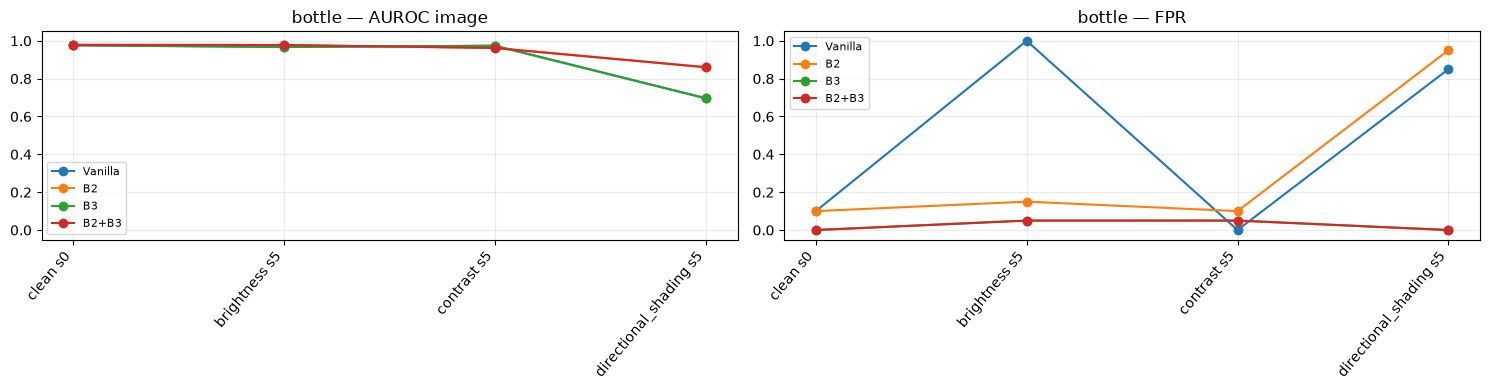

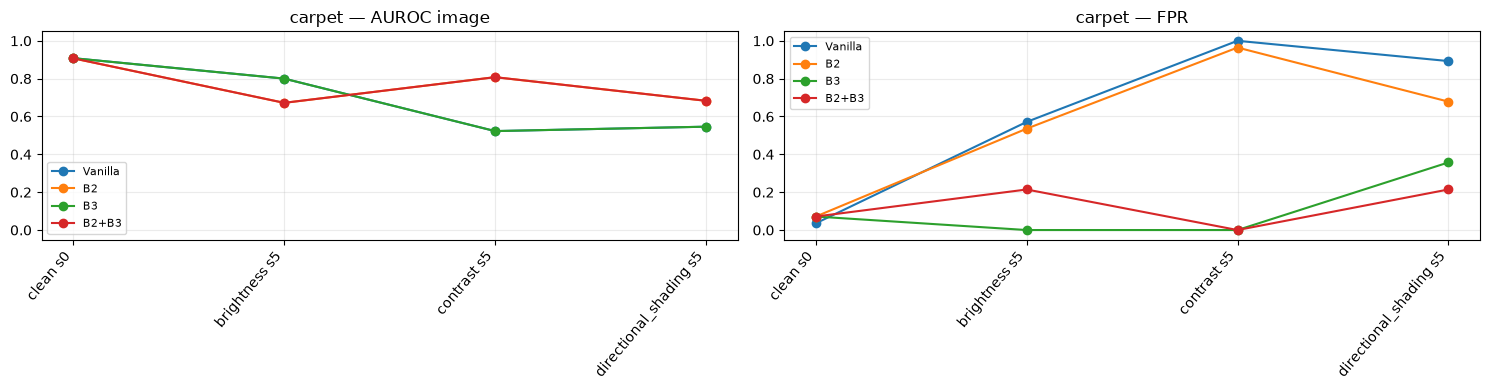

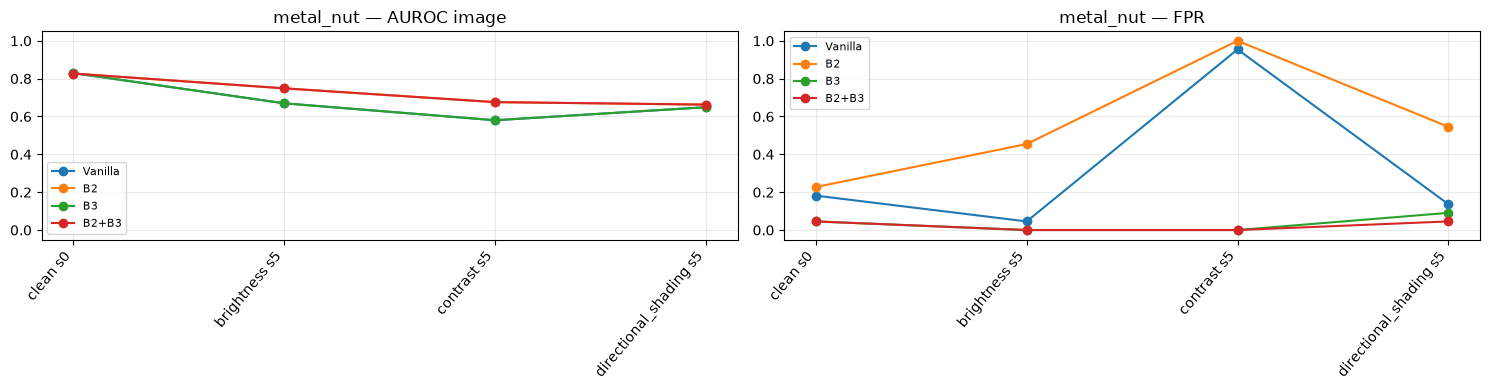

In [13]:
piv=RESULTS_DF.pivot_table(index=['category','shift','severity'],columns='method',values=['image_AUROC','FPR','F1'])
display(piv.round(3))
piv.to_csv(OUTPUT_DIR/'metrics'/'b2_b3_pivot.csv')
for cat in CATEGORIES:
    sub=RESULTS_DF[RESULTS_DF.category==cat]
    keys=list(dict.fromkeys(zip(sub['shift'],sub['severity'])))
    labels_x=[f'{k} s{s}' for k,s in keys]
    fig,axes=plt.subplots(1,2,figsize=(15,4))
    for method in ['Vanilla','B2','B3','B2+B3']:
        sm=sub[sub.method==method].set_index(['shift','severity'])
        ys_auc=[sm.loc[key,'image_AUROC'] for key in keys]
        ys_fpr=[sm.loc[key,'FPR'] for key in keys]
        axes[0].plot(range(len(keys)),ys_auc,marker='o',label=method)
        axes[1].plot(range(len(keys)),ys_fpr,marker='o',label=method)
    for ax,name in zip(axes,['AUROC image','FPR']):
        ax.set_title(f'{cat} — {name}');ax.set_xticks(range(len(keys)),labels_x,rotation=50,ha='right')
        ax.grid(alpha=.25);ax.set_ylim(-.05,1.05)
    axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/'figures'/f'{cat}_b2_b3_comparison.png',dpi=130)
    plt.show()

## Étape 13 — Heatmaps comparatives (optionnel)

Ces cartes servent uniquement à **illustrer** les scores. Elles ne sont pas utilisées pour ajuster les paramètres ; le masque réel est affiché pour interprétation.

In [14]:
SHOW_EXAMPLE_HEATMAPS=False
if SHOW_EXAMPLE_HEATMAPS:
    for cat in CATEGORIES:
        p=next(p for p in SPLITS[cat]['target_test'] if p.parent.name!='good')
        kind,sev=CONDITIONS[-1]; item=ADAPTATION[(cat,kind,sev)]
        (v,vm),(b2,bm)=predict_both(p,cat,kind,sev,item['target_stats'],True)
        with Image.open(p) as im:
            shifted=apply_lighting_shift(im,kind,sev,str(p.relative_to(MVTEC_ROOT))).resize((IMAGE_SIZE,IMAGE_SIZE))
        mask=load_mask(p,cat)
        fig,axes=plt.subplots(1,4,figsize=(14,3.7))
        axes[0].imshow(shifted);axes[0].set_title('Image sous shift')
        axes[1].imshow(mask,cmap='gray');axes[1].set_title('Masque')
        axes[2].imshow(shifted);axes[2].imshow(vm,cmap='jet',alpha=.5);axes[2].set_title(f'Vanilla {v:.2f}')
        axes[3].imshow(shifted);axes[3].imshow(bm,cmap='jet',alpha=.5);axes[3].set_title(f'B2 {b2:.2f}')
        for ax in axes: ax.axis('off')
        fig.tight_layout();fig.savefig(OUTPUT_DIR/'figures'/f'{cat}_b2_heatmap.png',dpi=140);plt.show()
else:
    print('Heatmaps facultatives désactivées. Mettre SHOW_EXAMPLE_HEATMAPS=True pour les générer.')

Heatmaps facultatives désactivées. Mettre SHOW_EXAMPLE_HEATMAPS=True pour les générer.


## Étape 14 — Enregistrer chaque méthode/condition dans MLflow

Un **run par catégorie × éclairage × méthode**. Le fichier CSV est enregistré indépendamment de MLflow. Si le serveur n'est pas disponible, les résultats locaux sont conservés.

Sur Docker, le tracking URI doit être `http://mlflow:5000`. Les ports et hôtes autorisés doivent correspondre au `docker-compose.yaml`.

In [15]:
if LOG_TO_MLFLOW:
    import mlflow
    MLFLOW_URI=os.getenv('MLFLOW_TRACKING_URI') or (OUTPUT_DIR/'mlruns').resolve().as_uri()
    mlflow.set_tracking_uri(MLFLOW_URI)
    try:
        mlflow.set_experiment('LightShift-PatchCore-B2-B3-CPU')
        for row in tqdm(RESULTS,desc='Runs MLflow'):
            cat=row['category'];kind=row['shift'];sev=row['severity'];method=row['method']
            with mlflow.start_run(run_name=f'{cat}_{kind}_s{sev}_{method.replace("+","_")}'):
                mlflow.set_tags({'stage':'B2_B3','method':method,'dataset':'MVTec AD synthétique','hardware':'CPU'})
                mlflow.log_params({'category':cat,'shift':kind,'severity':sev,'method':method,
                                   'alpha':ALPHA,'n_b2_align':N_B2_ALIGN,'n_b3_calib':N_B3_CALIB,
                                   'backbone':CFG['backbone'],'seed':SEED,'image_size':IMAGE_SIZE})
                mlflow.log_metrics({k:float(v) for k,v in row.items()
                                    if isinstance(v,(int,float,np.number)) and np.isfinite(v)})
                mlflow.log_artifact(str(OUTPUT_DIR/'config'/'b2_b3_cpu.yaml'),artifact_path='config')
                mlflow.log_artifact(str(OUTPUT_DIR/'config'/f'{cat}_adaptation_split.json'),artifact_path='config')
                figure=OUTPUT_DIR/'figures'/f'{cat}_b2_b3_comparison.png'
                if figure.exists(): mlflow.log_artifact(str(figure),artifact_path='figures')
        print('MLflow :',MLFLOW_URI)
    except Exception as exc:
        warnings.warn(f'MLflow indisponible : {type(exc).__name__}: {exc}. Résultats CSV conservés.')
else:
    print('MLflow désactivé ; CSV conservé.')

2026/11/08 21:39:33 INFO mlflow.tracking.fluent: Experiment with name 'LightShift-PatchCore-B2-B3-CPU' does not exist. Creating a new experiment.
Runs MLflow:   4%|▍         | 2/48 [00:00<00:08,  5.20it/s]

🏃 View run bottle_clean_s0_Vanilla at: http://mlflow:5000/#/experiments/3/runs/b4b6cd084671449e9c52c135a2df6087
🧪 View experiment at: http://mlflow:5000/#/experiments/3
🏃 View run bottle_clean_s0_B2 at: http://mlflow:5000/#/experiments/3/runs/af896e55aa454641a62ac334dad5ea7b
🧪 View experiment at: http://mlflow:5000/#/experiments/3


Runs MLflow:   8%|▊         | 4/48 [00:00<00:07,  6.07it/s]

🏃 View run bottle_clean_s0_B3 at: http://mlflow:5000/#/experiments/3/runs/41f1d34238ac4b3f89d0b6414adc8865
🧪 View experiment at: http://mlflow:5000/#/experiments/3
🏃 View run bottle_clean_s0_B2_B3 at: http://mlflow:5000/#/experiments/3/runs/d62d36bb0cc045a582ec0992968aa2a7
🧪 View experiment at: http://mlflow:5000/#/experiments/3


Runs MLflow:  12%|█▎        | 6/48 [00:01<00:06,  6.35it/s]

🏃 View run bottle_brightness_s5_Vanilla at: http://mlflow:5000/#/experiments/3/runs/9e2e53763e0c4096b2a47b2144cff64b
🧪 View experiment at: http://mlflow:5000/#/experiments/3
🏃 View run bottle_brightness_s5_B2 at: http://mlflow:5000/#/experiments/3/runs/8fdd17f2b91e4ffbaac5e5ed4ca5cf3f
🧪 View experiment at: http://mlflow:5000/#/experiments/3


... (44 outputs left out)

Runs MLflow:  96%|█████████▌| 46/48 [00:08<00:00,  5.85it/s]

🏃 View run metal_nut_directional_shading_s5_Vanilla at: http://mlflow:5000/#/experiments/3/runs/985109d32a5c49ed85e2eb49c9cff0c9
🧪 View experiment at: http://mlflow:5000/#/experiments/3
🏃 View run metal_nut_directional_shading_s5_B2 at: http://mlflow:5000/#/experiments/3/runs/5092ca25a7dc4afd9cc7ab54e3d8fca8
🧪 View experiment at: http://mlflow:5000/#/experiments/3


Runs MLflow: 100%|██████████| 48/48 [00:08<00:00,  5.74it/s]

🏃 View run metal_nut_directional_shading_s5_B3 at: http://mlflow:5000/#/experiments/3/runs/ed30385cbb344465b3b3daa422a502eb
🧪 View experiment at: http://mlflow:5000/#/experiments/3
🏃 View run metal_nut_directional_shading_s5_B2_B3 at: http://mlflow:5000/#/experiments/3/runs/9db034bc91b14a979874444e36334998
🧪 View experiment at: http://mlflow:5000/#/experiments/3
MLflow : http://mlflow:5000


## Étape 15 — Bilan et suite (B1 puis B4)

- **B1 (notebook 04)** : construire des banques augmentées à **budget coreset constant** et comparer leur robustesse.
- **B4 (notebook dédié)** : apprendre sur CPU un **adaptateur résiduel 1×1** au-dessus de features gelées, avec des paires photométriques provenant **uniquement des images source normales**, une perte de consistance/contrastive et un suivi MLflow (`train_loss`, `val_loss`, temps, seed, checkpoints). Il faudra reconstruire la banque dans l'espace adapté pour comparer équitablement B4 et B1+B2+B3 ; ne pas utiliser le test pour l'entraînement ni les choix d'hyperparamètres.

**Limitations :** B2 normalisation canal par canal ne garantit pas l'amélioration du ranking ; B3 contrôle marginal du FPR sous échangeabilité, et une calibration de 20 images avec α=0,05 est très conservative. Les conditions et la réalisation des ablations doivent être fixées sans sélection sur les résultats test.

In [16]:
SUMMARY={'project':'LightShift-PatchCore','notebook':'03_b2_b3_cpu','config':PROTOCOL,
         'n_results':len(RESULTS_DF),'metrics_csv':str(METRICS_PATH),
         'data_root':str(MVTEC_ROOT),'next_steps':['04_B1','05_B4_CPU']}
summary_path=OUTPUT_DIR/'metrics'/'b2_b3_summary.json'
summary_path.write_text(json.dumps(SUMMARY,indent=2,default=str),encoding='utf-8')
print('B2 + B3 terminé. Résultats :',METRICS_PATH)
print('Puis : B1, et B4 avec entraînement léger CPU et MLflow.')

B2 + B3 terminé. Résultats : /workspace/notebooks/artifacts_b2_b3/metrics/b2_b3_results.csv
Puis : B1, et B4 avec entraînement léger CPU et MLflow.
